In [19]:
#Phase 1 — Data Understanding

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import io

# Upload the Sample Superstore Excel file
uploaded = files.upload()

filename = next(iter(uploaded))

# Load dataset
df = pd.read_excel(io.BytesIO(uploaded[filename]))

# Basic inspection
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nData Types and Non-Null Counts:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Saving sample_-_superstore.xls to sample_-_superstore (2).xls
Dataset Shape: (10194, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840



Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country/Region,0
City,0



Duplicate Rows: 0

Statistical Summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Row ID,10194.0,NaN,NaN,NaN,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order ID,10194,5111,US-2026-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,10194,NaN,NaN,NaN,2025-04-29 11:48:25.002942720,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
Ship Date,10194,NaN,NaN,NaN,2025-05-03 10:52:45.626839296,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
Ship Mode,10194,4,Standard Class,6120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,10194,804,WB-21850,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,10194,800,William Brown,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,10194,3,Consumer,5281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country/Region,10194,2,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,10194,542,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Check dataset dates and geographic coverage
print("Dataset Date Range:")
print("First Order:", df["Order Date"].min())
print("Last Order:", df["Order Date"].max())

print("\nCountry-wise Records:")
display(df["Country/Region"].value_counts())

print("\nYear-wise Records:")
display(df["Order Date"].dt.year.value_counts().sort_index())

print("\nUnique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Products:", df["Product ID"].nunique())

# Check possible data-quality issues
print("\nFuture-dated Orders:")
display(df[df["Order Date"] > pd.Timestamp("2026-11-06")][
    ["Order ID", "Order Date", "Ship Date"]
].head(10))

print("\nShip Date Before Order Date:")
display(df[df["Ship Date"] < df["Order Date"]])

print("\nNegative Sales:")
display(df[df["Sales"] < 0])

print("\nDiscount Range:")
print(df["Discount"].min(), "to", df["Discount"].max())

Dataset Date Range:
First Order: 2023-01-03 00:00:00
Last Order: 2026-12-30 00:00:00

Country-wise Records:


,count
Country/Region,
United States,9994
Canada,200



Year-wise Records:


,count
Order Date,
2023,2051
2024,2130
2025,2634
2026,3379



Unique Orders: 5111
Unique Customers: 804
Unique Products: 1862

Future-dated Orders:


,Order ID,Order Date,Ship Date
9366,US-2026-113460,2026-11-07,2026-11-09
9367,US-2026-149888,2026-11-07,2026-11-13
9368,US-2026-132346,2026-11-07,2026-11-11
9369,US-2026-163188,2026-11-07,2026-11-07
9370,US-2026-152737,2026-11-07,2026-11-12
9371,US-2026-113572,2026-11-07,2026-11-11
9372,US-2026-122504,2026-11-07,2026-11-12
9373,US-2026-152737,2026-11-07,2026-11-12
9374,US-2026-122504,2026-11-07,2026-11-12
9375,US-2026-149888,2026-11-07,2026-11-13



Ship Date Before Order Date:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit



Negative Sales:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit



Discount Range:
0.0 to 0.8


In [8]:
# 1. Count future-dated records
cutoff_date = pd.Timestamp("2026-11-06")

future_rows = df[df["Order Date"] > cutoff_date]

print("Future-dated rows:", len(future_rows))
print("Future-dated percentage:",
      round(len(future_rows) / len(df) * 100, 2), "%")

# 2. Country-wise date range
country_dates = df.groupby("Country/Region").agg(
    Total_Rows=("Order ID", "count"),
    First_Order=("Order Date", "min"),
    Last_Order=("Order Date", "max"),
    Unique_Customers=("Customer ID", "nunique")
)

display(country_dates)

# 3. Check unique Row IDs
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

# 4. Check invalid numerical values
print("Zero or negative sales:", (df["Sales"] <= 0).sum())
print("Zero or negative quantity:", (df["Quantity"] <= 0).sum())
print("Negative discounts:", (df["Discount"] < 0).sum())
print("Discount above 100%:", (df["Discount"] > 1).sum())

# 5. Check country-wise future records
display(
    future_rows["Country/Region"].value_counts()
)

Future-dated rows: 828
Future-dated percentage: 8.12 %


,Total_Rows,First_Order,Last_Order,Unique_Customers
Country/Region,,,,
Canada,200,2023-01-21,2026-12-30,37
United States,9994,2023-01-03,2026-12-30,793


Duplicate Row IDs: 0
Zero or negative sales: 0
Zero or negative quantity: 0
Negative discounts: 0
Discount above 100%: 0


,count
Country/Region,
United States,807
Canada,21


In [9]:
# Check uploaded file details
print("Uploaded filename:", filename)
print("Total file size (MB):",
      round(len(uploaded[filename]) / (1024 * 1024), 2))

# Check order IDs by year
display(
    df.groupby(df["Order Date"].dt.year)["Order ID"]
      .nunique()
)

Uploaded filename: sample_-_superstore (1).xls
Total file size (MB): 3.26


,Order ID
Order Date,
2023,995
2024,1053
2025,1340
2026,1723


In [10]:
print(df.groupby("Country/Region").size())
print(df.groupby(df["Order Date"].dt.year).size())
print(df.groupby("Country/Region")["Order Date"].agg(["min", "max"]))

Country/Region
Canada            200
United States    9994
dtype: int64
Order Date
2023    2051
2024    2130
2025    2634
2026    3379
dtype: int64
                      min        max
Country/Region                      
Canada         2023-01-21 2026-12-30
United States  2023-01-03 2026-12-30


In [21]:
# Keep an untouched copy of the original dataset
df_raw = df.copy()

# Create a separate working copy for cleaning
df_clean = df_raw.copy()

print("Original Shape:", df_raw.shape)
print("Working Copy Shape:", df_clean.shape)

# Check leading/trailing spaces in text columns
text_columns = df_clean.select_dtypes(include="object").columns

print("\nWhitespace Issues:")
for col in text_columns:
    count = df_clean[col].ne(df_clean[col].str.strip()).sum()
    if count > 0:
        print(f"{col}: {count} rows")

# Check blank strings
print("\nBlank String Counts:")
for col in text_columns:
    count = df_clean[col].str.strip().eq("").sum()
    if count > 0:
        print(f"{col}: {count} rows")

# Check date validity
print("\nDate Validation:")
print("Ship date before order date:",
      (df_clean["Ship Date"] < df_clean["Order Date"]).sum())

# Check numerical ranges
print("\nNumerical Validation:")
print("Sales <= 0:", (df_clean["Sales"] <= 0).sum())
print("Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Discount outside 0–1:",
      ((df_clean["Discount"] < 0) |
       (df_clean["Discount"] > 1)).sum())

# Check category values
for col in ["Segment", "Region", "Category", "Ship Mode"]:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())


Original Shape: (10194, 21)
Working Copy Shape: (10194, 21)

Whitespace Issues:
Postal Code: 9983 rows

Blank String Counts:

Date Validation:
Ship date before order date: 0

Numerical Validation:
Sales <= 0: 0
Quantity <= 0: 0
Discount outside 0–1: 0

Segment:
Segment
Consumer       5281
Corporate      3090
Home Office    1823
Name: count, dtype: int64

Region:
Region
West       3253
East       2986
Central    2335
South      1620
Name: count, dtype: int64

Category:
Category
Office Supplies    6128
Furniture          2201
Technology         1865
Name: count, dtype: int64

Ship Mode:
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64


In [22]:
#Phase 2: Data Cleaning & Validation
# Inspect actual Postal Code values and their data types
print("Column Data Type:", df_clean["Postal Code"].dtype)

print("\nFirst 15 Postal Codes:")
for value in df_clean["Postal Code"].head(15):
    print(repr(value), type(value))

print("\nUnique Python Data Types:")
print(df_clean["Postal Code"].apply(
    lambda x: type(x).__name__
).value_counts())

print("\nMissing Postal Codes:")
print(df_clean["Postal Code"].isna().sum())

Column Data Type: object

First 15 Postal Codes:
77095 <class 'int'>
60540 <class 'int'>
60540 <class 'int'>
60540 <class 'int'>
19143 <class 'int'>
42420 <class 'int'>
42420 <class 'int'>
30605 <class 'int'>
42420 <class 'int'>
42420 <class 'int'>
42420 <class 'int'>
90049 <class 'int'>
42420 <class 'int'>
42420 <class 'int'>
77340 <class 'int'>

Unique Python Data Types:
Postal Code
int    9983
str     211
Name: count, dtype: int64

Missing Postal Codes:
0


In [13]:
# Extract postal codes stored as strings
string_postal_codes = df_clean[
    df_clean["Postal Code"].apply(lambda x: isinstance(x, str))
]["Postal Code"]

print("Total String Values:", len(string_postal_codes))

print("\nString Values:")
print(string_postal_codes.value_counts().head(30))

print("\nValues with Leading or Trailing Spaces:")
print([
    repr(x) for x in string_postal_codes
    if x != x.strip()
][:20])

print("\nUnique String Values:")
print(string_postal_codes.nunique())

Total String Values: 211

String Values:
Postal Code
H1A      24
M3C      22
M7A      20
G1B      16
T2C      14
M5H      12
05401    11
C0A      10
R0H       8
V6B       8
E1A       8
T5A       8
A0A       6
B3H       6
V6Z       6
H1C       6
H1B       4
V6G       4
M2N       4
T1Y       4
R3R       4
V5K       2
V6E       2
S0G       2
Name: count, dtype: int64

Values with Leading or Trailing Spaces:
[]

Unique String Values:
24


In [14]:
# Convert Postal Code to string without losing leading zeros
df_clean["Postal Code"] = (
    df_clean["Postal Code"]
    .astype("string")
    .str.strip()
)

# Verify the conversion
print("New Data Type:", df_clean["Postal Code"].dtype)

print("\nSample Postal Codes:")
display(df_clean[["Country/Region", "Postal Code"]].head(15))

print("\nMissing Values:", df_clean["Postal Code"].isna().sum())

print("\nPostal Code Data Types:")
print(df_clean["Postal Code"].apply(
    lambda x: type(x).__name__
).value_counts())

New Data Type: string

Sample Postal Codes:


,Country/Region,Postal Code
0,United States,77095
1,United States,60540
2,United States,60540
3,United States,60540
4,United States,19143
5,United States,42420
6,United States,42420
7,United States,30605
8,United States,42420
9,United States,42420



Missing Values: 0

Postal Code Data Types:
Postal Code
str    10194
Name: count, dtype: int64


In [15]:
# Identify all text columns
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

# Count values that need trimming
print("Whitespace issues before cleaning:")

for col in text_cols:
    count = (
        df_clean[col].notna() &
        df_clean[col].ne(df_clean[col].str.strip())
    ).sum()

    if count > 0:
        print(col, ":", count)

# Remove unnecessary leading/trailing spaces
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Verify
print("\nRemaining whitespace issues:")

for col in text_cols:
    count = (
        df_clean[col].notna() &
        df_clean[col].ne(df_clean[col].str.strip())
    ).sum()

    if count > 0:
        print(col, ":", count)

print("\nFinal Shape:", df_clean.shape)
print("Missing Values:", df_clean.isnull().sum().sum())

Whitespace issues before cleaning:

Remaining whitespace issues:

Final Shape: (10194, 21)
Missing Values: 0


In [16]:
# Check final dataset structure
print("Dataset Shape:", df_clean.shape)

# Check missing values and duplicates
print("\nTotal Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Duplicate Row IDs:", df_clean["Row ID"].duplicated().sum())

# Check data types
print("\nColumn Data Types:")
display(df_clean.dtypes)

# Validate numerical columns
print("\nNumerical Summary:")
display(df_clean[["Sales", "Quantity", "Discount", "Profit"]].describe())

# Check date consistency
print("\nDate Validation:")
print("Invalid Shipping Dates:",
      (df_clean["Ship Date"] < df_clean["Order Date"]).sum())

# Check category consistency
for col in ["Segment", "Region", "Category", "Ship Mode", "Country/Region"]:
    print(f"\n{col}: {df_clean[col].nunique()} unique values")
    print(df_clean[col].unique())

Dataset Shape: (10194, 21)

Total Missing Values: 0
Duplicate Rows: 0
Duplicate Row IDs: 0

Column Data Types:


,0
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country/Region,object
City,object



Numerical Summary:


,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000



Date Validation:
Invalid Shipping Dates: 0

Segment: 3 unique values
['Consumer' 'Home Office' 'Corporate']

Region: 4 unique values
['Central' 'East' 'South' 'West']

Category: 3 unique values
['Office Supplies' 'Furniture' 'Technology']

Ship Mode: 4 unique values
['Standard Class' 'First Class' 'Second Class' 'Same Day']

Country/Region: 2 unique values
['United States' 'Canada']


In [17]:
#Phase 3: Exploratory Data Analysis (EDA)

========== BUSINESS PERFORMANCE ==========
Total Sales: $2,326,534.35
Total Profit: $292,296.81
Total Orders: 5,111
Total Customers: 804
Total Quantity Sold: 38,654
Profit Margin: 12.56%


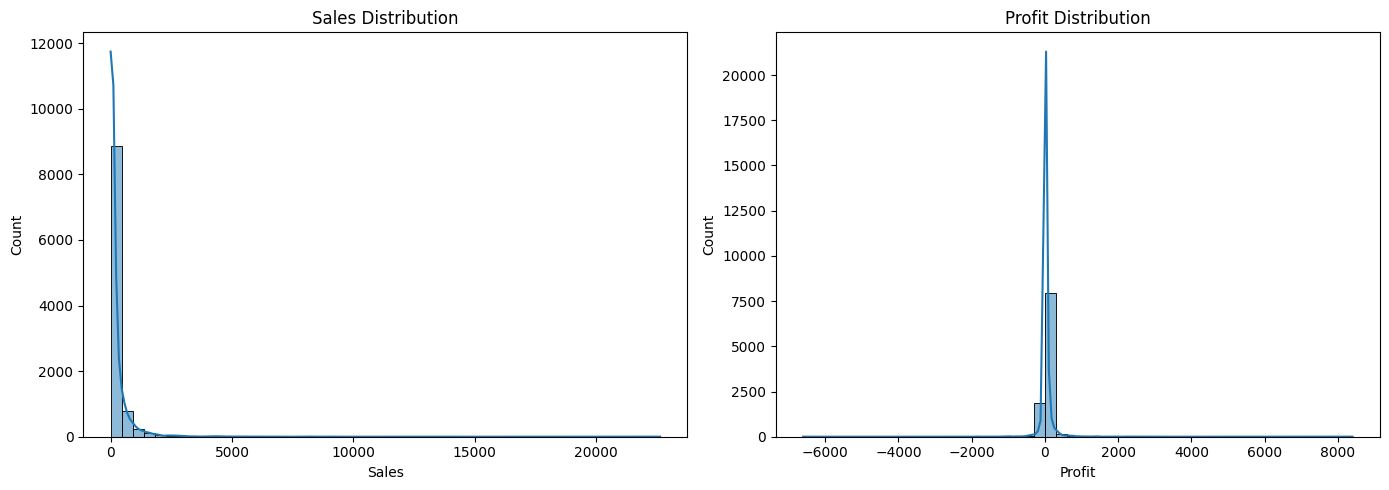

In [18]:
# Step 1: Overall Business Performance

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate key business metrics
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer ID"].nunique()
total_quantity = df_clean["Quantity"].sum()
profit_margin = (total_profit / total_sales) * 100

# Display KPI summary
print("========== BUSINESS PERFORMANCE ==========")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

# Create Sales and Profit visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["Sales"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Sales Distribution")
axes[0].set_xlabel("Sales")

sns.histplot(df_clean["Profit"], bins=50, kde=True, ax=axes[1])
axes[1].set_title("Profit Distribution")
axes[1].set_xlabel("Profit")

plt.tight_layout()
plt.show()

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
2,Technology,839893.28,146543.38,7017,1560,17.45
0,Furniture,754747.76,19730.00,8369,1819,2.61
1,Office Supplies,731893.31,126023.44,23268,3812,17.22


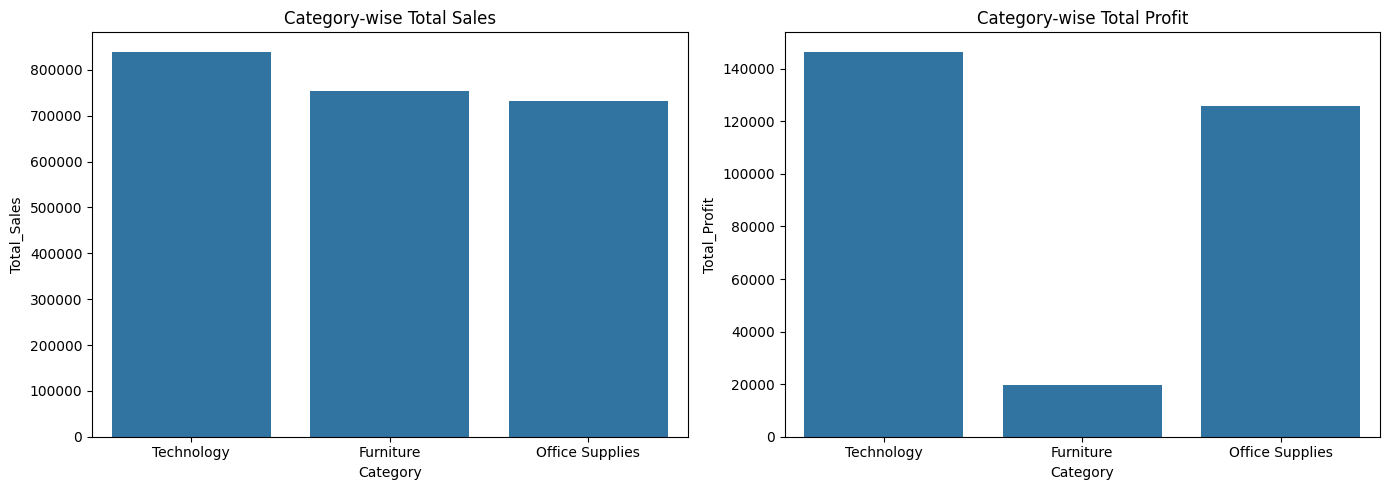

In [23]:
# Step 2: Category-wise Business Analysis

category_analysis = df_clean.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin
category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"]
) * 100

# Sort by total sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales", ascending=False
)

display(category_analysis.round(2))

# Visualize category performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales",
    ax=axes[0]
)
axes[0].set_title("Category-wise Total Sales")
axes[0].ticklabel_format(style="plain", axis="y")

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Profit",
    ax=axes[1]
)
axes[1].set_title("Category-wise Total Profit")
axes[1].ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
3,Furniture,Tables,208020.18,-17753.21,1261,-8.53
0,Furniture,Bookcases,115361.20,-3632.07,878,-3.15
12,Office Supplies,Supplies,46725.50,-1171.39,653,-2.51
8,Office Supplies,Fasteners,8532.24,2428.64,980,28.46
15,Technology,Machines,189925.03,3461.98,442,1.82
9,Office Supplies,Labels,12695.04,5572.78,1410,43.90
5,Office Supplies,Art,27659.01,6653.20,3092,24.05
7,Office Supplies,Envelopes,16528.36,6988.02,914,42.28
2,Furniture,Furnishings,95598.13,13891.74,3799,14.53
4,Office Supplies,Appliances,108213.18,18329.48,1750,16.94


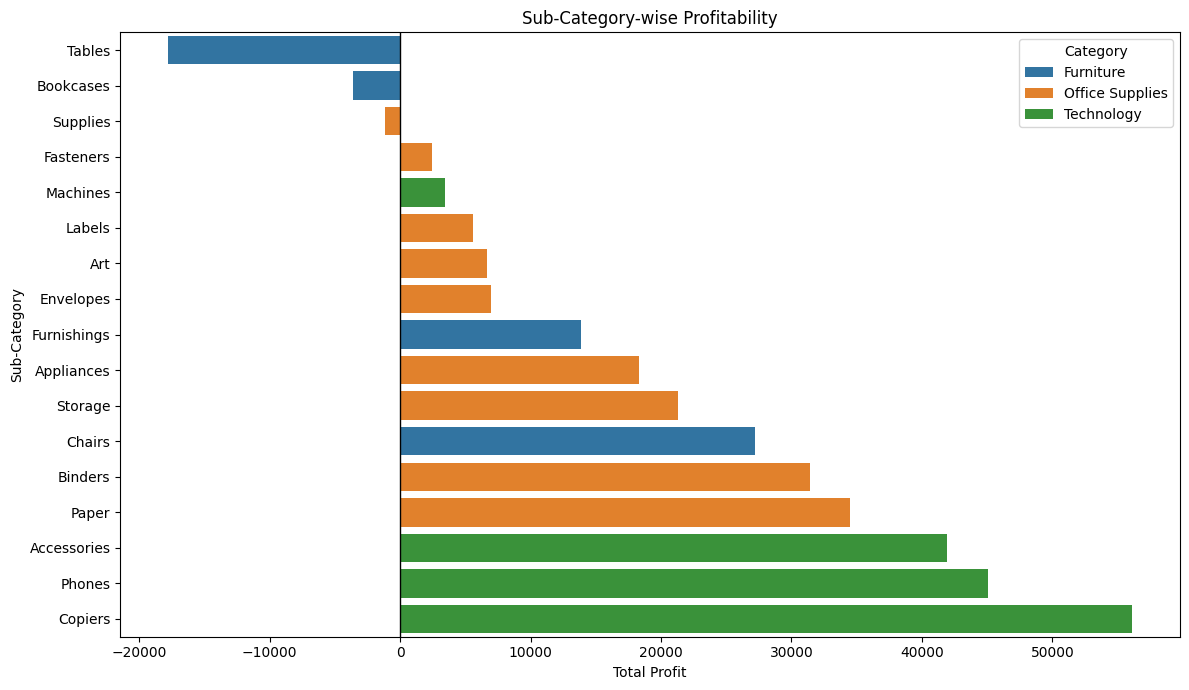

In [24]:
# Step 3: Sub-Category Profitability Analysis

subcategory_analysis = df_clean.groupby(
    ["Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate profit margin
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"] /
    subcategory_analysis["Total_Sales"]
) * 100

# Sort by profit
subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit", ascending=True
)

display(subcategory_analysis.round(2))

# Visualize sub-category profitability
plt.figure(figsize=(12, 7))

sns.barplot(
    data=subcategory_analysis,
    x="Total_Profit",
    y="Sub-Category",
    hue="Category"
)

plt.title("Sub-Category-wise Profitability")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

,Discount_Band,Total_Sales,Total_Profit,Total_Orders,Average_Discount,Profit_Margin_%
0,High Discount,129294.87,-100029.73,753,0.70,-77.37
1,Low Discount,856450.41,101598.91,2541,0.20,11.86
2,Medium Discount,235465.28,-35990.96,404,0.35,-15.29
3,No Discount,1105323.79,326718.59,2714,0.00,29.56


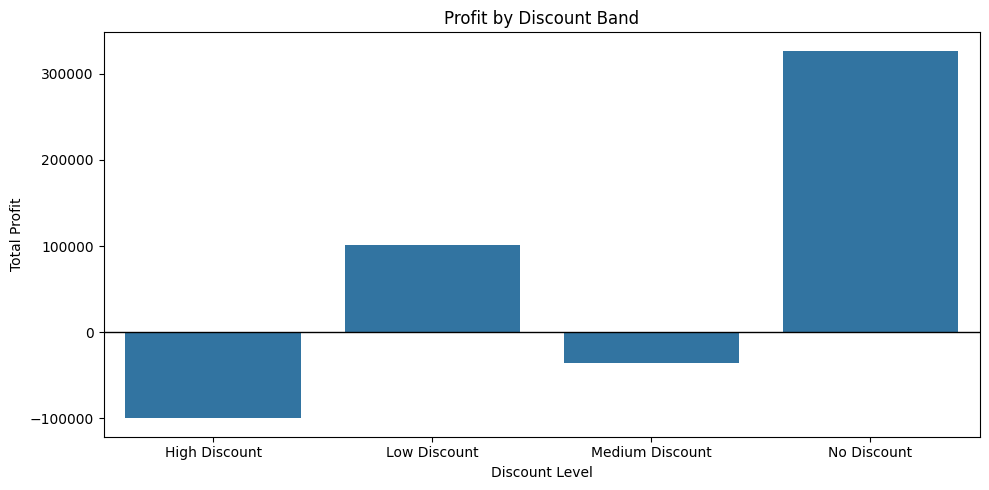

In [25]:
# Step 4: Discount Impact on Profitability

# Create discount groups
df_clean["Discount_Band"] = np.select(
    [
        df_clean["Discount"] == 0,
        df_clean["Discount"] <= 0.2,
        df_clean["Discount"] <= 0.4,
        df_clean["Discount"] > 0.4
    ],
    [
        "No Discount",
        "Low Discount",
        "Medium Discount",
        "High Discount"
    ],
    default="Other"
)

# Analyze profitability by discount band
discount_analysis = df_clean.groupby(
    "Discount_Band", observed=True
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Average_Discount=("Discount", "mean")
).reset_index()

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"]
) * 100

display(discount_analysis.round(2))

# Visualize discount vs profit
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis,
    x="Discount_Band",
    y="Total_Profit"
)

plt.title("Profit by Discount Band")
plt.xlabel("Discount Level")
plt.ylabel("Total Profit")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

,Category,Discount_Band,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
2,Furniture,Medium Discount,160299.04,-29365.36,1238,-18.32
0,Furniture,High Discount,36124.39,-25590.92,869,-70.84
1,Furniture,Low Discount,298169.26,15209.29,2835,5.10
3,Furniture,No Discount,260155.06,59476.99,3427,22.86
4,Office Supplies,High Discount,39633.89,-47224.26,2714,-119.15
6,Office Supplies,Medium Discount,606.56,-81.98,5,-13.52
5,Office Supplies,Low Discount,239242.26,39437.78,8434,16.48
7,Office Supplies,No Discount,452410.61,133891.90,12115,29.60
8,Technology,High Discount,53536.58,-27214.55,121,-50.83
10,Technology,Medium Discount,74559.68,-6543.61,506,-8.78


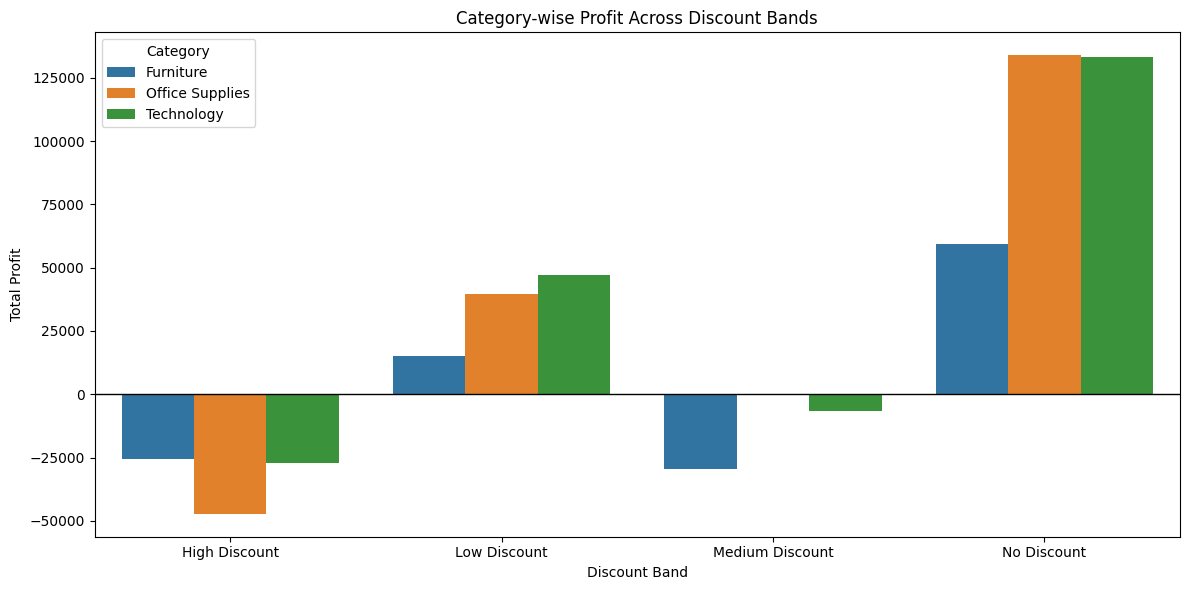

In [26]:
# Step 5: Category-wise Discount Impact

category_discount = df_clean.groupby(
    ["Category", "Discount_Band"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate profit margin
category_discount["Profit_Margin_%"] = (
    category_discount["Total_Profit"] /
    category_discount["Total_Sales"]
) * 100

display(
    category_discount.sort_values(
        by=["Category", "Total_Profit"]
    ).round(2)
)

# Visualize category-wise profit by discount band
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_discount,
    x="Discount_Band",
    y="Total_Profit",
    hue="Category"
)

plt.title("Category-wise Profit Across Discount Bands")
plt.xlabel("Discount Band")
plt.ylabel("Total Profit")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Total_Customers,Profit_Margin_%
3,West,739813.61,110798.82,1635,12466,686,14.98
1,East,691828.17,94883.26,1475,11159,685,13.71
2,South,391721.90,46749.43,822,6209,512,11.93
0,Central,503170.67,39865.31,1179,8820,629,7.92


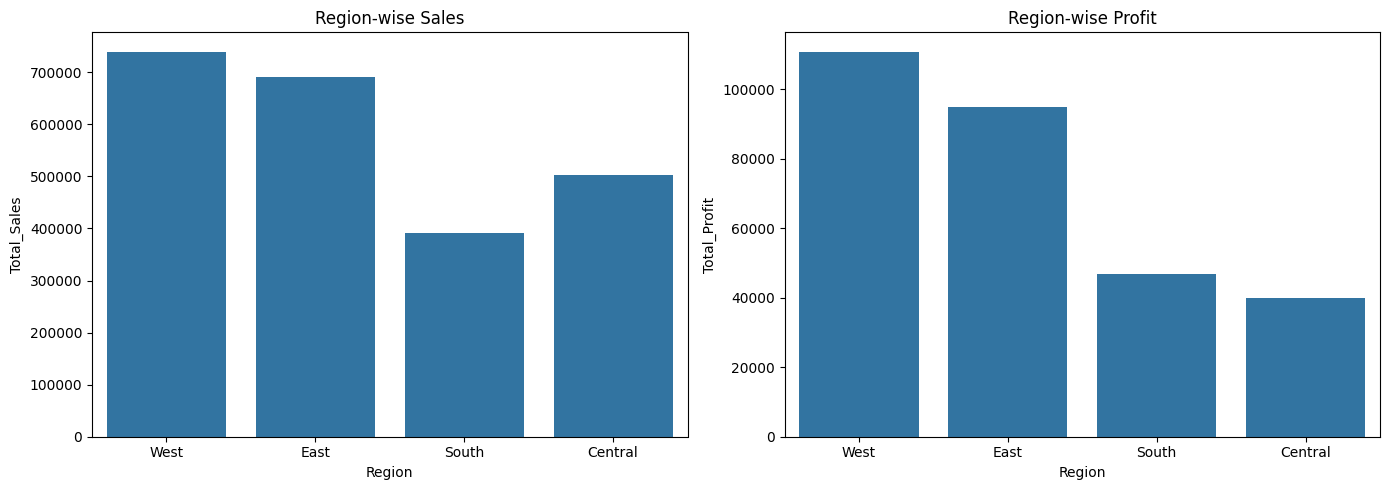

In [27]:
# Step 6: Region-wise Business Performance

region_analysis = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Total_Customers=("Customer ID", "nunique")
).reset_index()

# Calculate profit margin
region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"]
) * 100

# Sort by profit
region_analysis = region_analysis.sort_values(
    by="Total_Profit", ascending=False
)

display(region_analysis.round(2))

# Visualize regional performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales",
    ax=axes[0]
)
axes[0].set_title("Region-wise Sales")

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Profit",
    ax=axes[1]
)
axes[1].set_title("Region-wise Profit")

plt.tight_layout()
plt.show()

Historical Records: 9366
Future-Dated Records: 828


,Year_Month,Total_Sales,Total_Profit
32,2025-09,73521.66,9370.10
33,2025-10,59831.00,16256.84
34,2025-11,79411.97,4011.41
35,2025-12,97502.28,17926.30
36,2026-01,44259.21,7231.64
37,2026-02,20301.13,1613.87
38,2026-03,60728.48,15013.09
39,2026-04,36779.04,957.53
40,2026-05,45155.48,6299.81
41,2026-06,53056.08,8246.57


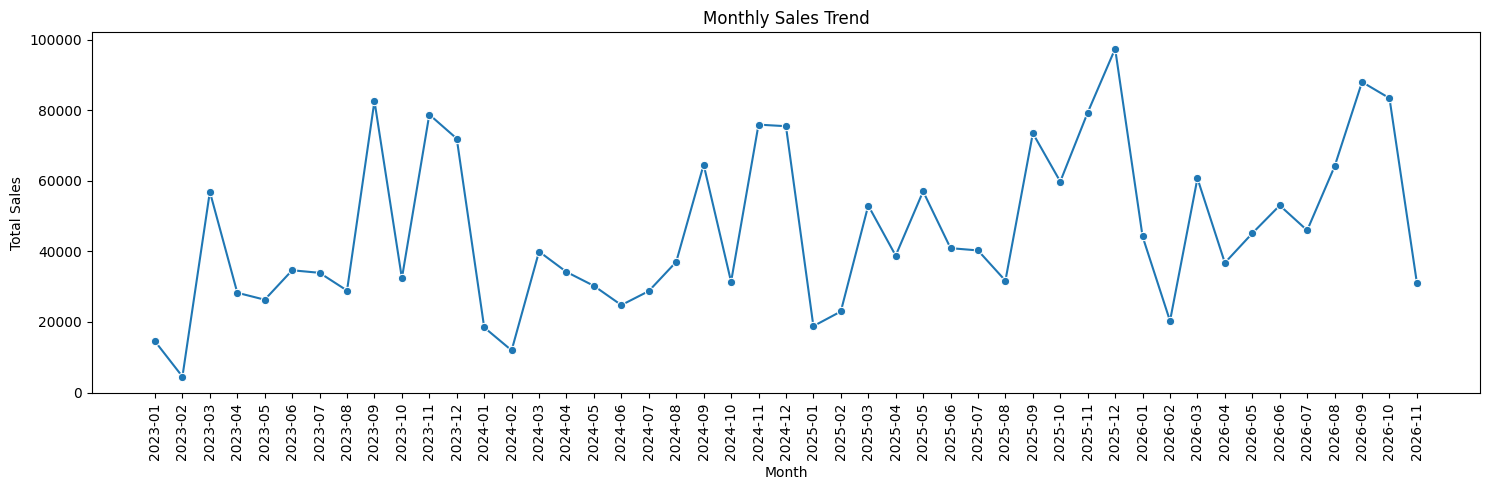

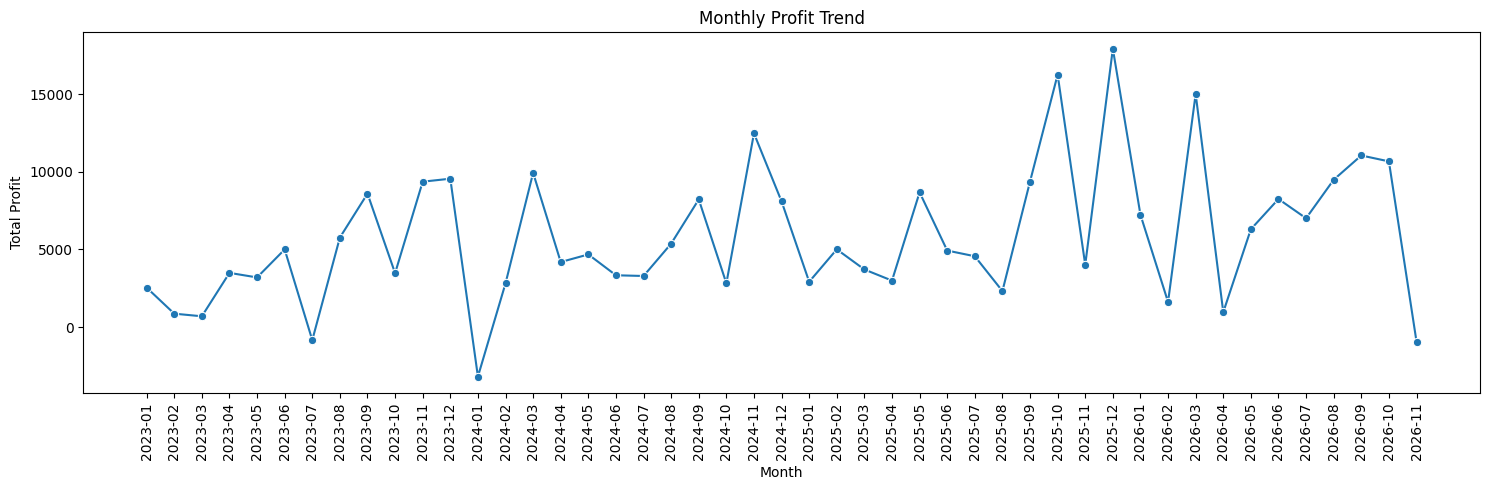

In [28]:
# Step 7: Monthly Sales and Profit Trend

# Set analysis cutoff date
cutoff_date = pd.Timestamp("2026-11-06")

# Separate historical and future-dated records
historical_df = df_clean[
    df_clean["Order Date"] <= cutoff_date
].copy()

future_df = df_clean[
    df_clean["Order Date"] > cutoff_date
].copy()

print("Historical Records:", len(historical_df))
print("Future-Dated Records:", len(future_df))

# Create monthly sales and profit summary
historical_df["Year_Month"] = (
    historical_df["Order Date"].dt.to_period("M").astype(str)
)

monthly_analysis = historical_df.groupby("Year_Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

display(monthly_analysis.tail(15).round(2))

# Monthly sales trend
plt.figure(figsize=(15, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Year_Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Monthly profit trend
plt.figure(figsize=(15, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Year_Month",
    y="Total_Profit",
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [29]:
# Step 8: Customer-Level Business Analysis

customer_analysis = df_clean.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate customer profit margin
customer_analysis["Profit_Margin_%"] = (
    customer_analysis["Total_Profit"] /
    customer_analysis["Total_Sales"]
) * 100

# Sort customers by sales
top_sales_customers = customer_analysis.sort_values(
    by="Total_Sales", ascending=False
).head(10)

# Sort customers by profit
top_profit_customers = customer_analysis.sort_values(
    by="Total_Profit", ascending=False
).head(10)

print("TOP 10 CUSTOMERS BY SALES")
display(top_sales_customers.round(2))

print("TOP 10 CUSTOMERS BY PROFIT")
display(top_profit_customers.round(2))

TOP 10 CUSTOMERS BY SALES


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%
711,SM-20320,Sean Miller,25043.05,-1980.74,5,50,-7.91
752,TC-20980,Tamara Chand,19052.22,8981.32,5,42,47.14
632,RB-19360,Raymond Buch,15117.34,6976.10,6,71,46.15
741,TA-21385,Tom Ashbrook,14595.62,4703.79,4,36,32.23
6,AB-10105,Adrian Barton,14473.57,5444.81,10,73,37.62
443,KL-16645,Ken Lonsdale,14175.23,806.85,12,113,5.69
680,SC-20095,Sanjit Chand,14142.33,5757.41,9,87,40.71
328,HL-15040,Hunter Lopez,12873.30,5622.43,6,50,43.68
694,SE-20110,Sanjit Engle,12209.44,2650.68,11,78,21.71
132,CC-12370,Christopher Conant,12129.07,2177.05,5,34,17.95


TOP 10 CUSTOMERS BY PROFIT


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%
752,TC-20980,Tamara Chand,19052.22,8981.32,5,42,47.14
632,RB-19360,Raymond Buch,15117.34,6976.10,6,71,46.15
680,SC-20095,Sanjit Chand,14142.33,5757.41,9,87,40.71
328,HL-15040,Hunter Lopez,12873.30,5622.43,6,50,43.68
6,AB-10105,Adrian Barton,14473.57,5444.81,10,73,37.62
741,TA-21385,Tom Ashbrook,14595.62,4703.79,4,36,32.23
161,CM-12385,Christopher Martinez,8954.02,3899.89,4,34,43.55
433,KD-16495,Keith Dawkins,8181.26,3038.63,12,84,37.14
48,AR-10540,Andy Reiter,6608.45,2884.62,6,33,43.65
235,DR-12940,Daniel Raglin,8350.87,2869.08,8,57,34.36


,Customer_Type,Total_Customers,Total_Orders,Total_Sales,Total_Profit,Sales_Contribution_%
0,One-Time Customer,12,12,5167.64,767.37,0.22
1,Repeat Customer,792,5105,2321366.71,291529.44,99.78


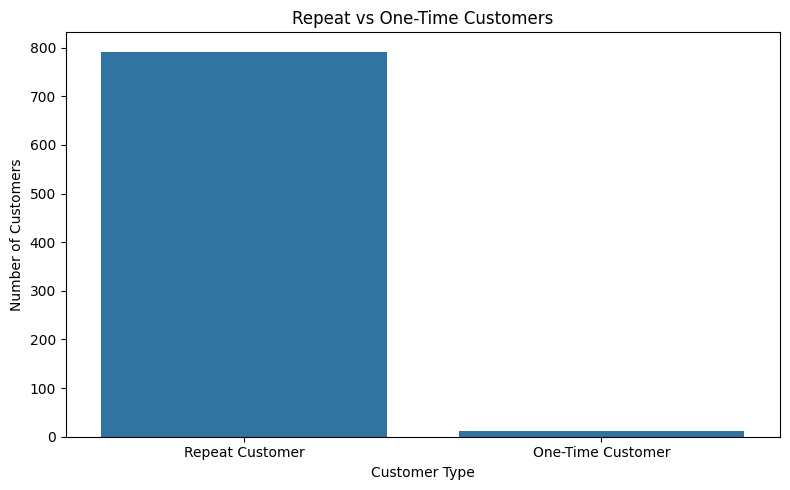

In [30]:
# Step 8.2: Repeat vs One-Time Customer Analysis

customer_frequency = df_clean.groupby("Customer ID").agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

# Classify customers by order frequency
customer_frequency["Customer_Type"] = np.where(
    customer_frequency["Total_Orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

# Summarize customer types
frequency_summary = customer_frequency.groupby(
    "Customer_Type"
).agg(
    Total_Customers=("Customer ID", "count"),
    Total_Orders=("Total_Orders", "sum"),
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Total_Profit", "sum")
).reset_index()

# Calculate revenue contribution
frequency_summary["Sales_Contribution_%"] = (
    frequency_summary["Total_Sales"] /
    frequency_summary["Total_Sales"].sum()
) * 100

display(frequency_summary.round(2))

# Visualize customer distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_frequency,
    x="Customer_Type"
)

plt.title("Repeat vs One-Time Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [31]:
# Step 8.3: Verify Order-Customer Relationship

orders_per_customer = df_clean.groupby(
    "Order ID"
)["Customer ID"].nunique()

multi_customer_orders = orders_per_customer[
    orders_per_customer > 1
]

print("Total Unique Orders:", df_clean["Order ID"].nunique())

print(
    "Orders Linked to Multiple Customers:",
    len(multi_customer_orders)
)

print("\nOrder IDs with Multiple Customers:")
display(multi_customer_orders)

Total Unique Orders: 5111
Orders Linked to Multiple Customers: 2

Order IDs with Multiple Customers:


,Customer ID
Order ID,
CA-2025-121465,4
CA-2026-130494,4


In [32]:
# Step 8.4: Inspect Orders Linked to Multiple Customers

problem_orders = ["CA-2025-121465", "CA-2026-130494"]

display(
    df_clean[
        df_clean["Order ID"].isin(problem_orders)
    ][[
        "Order ID",
        "Customer ID",
        "Customer Name",
        "Order Date",
        "Product ID",
        "Sales",
        "Profit"
    ]].sort_values(["Order ID", "Customer ID"])
)

,Order ID,Customer ID,Customer Name,Order Date,Product ID,Sales,Profit
5012,CA-2025-121465,HO-15231,Harry Olson,2025-06-12,OFF-BI-10002414,310.120,80.6312
5011,CA-2025-121465,HO-15232,Harry Olson,2025-06-12,OFF-AR-10003696,70.464,22.9008
5010,CA-2025-121465,HO-15233,Harry Olson,2025-06-12,FUR-CH-10004495,19.680,6.8880
5009,CA-2025-121465,HO-15234,Harry Olson,2025-06-12,FUR-CH-10001270,140.670,54.8613
7194,CA-2026-130494,HO-15231,Harry Olson,2026-03-16,OFF-BI-10002414,310.120,80.6312
7193,CA-2026-130494,HO-15232,Harry Olson,2026-03-16,OFF-AR-10003696,70.464,22.9008
7192,CA-2026-130494,HO-15233,Harry Olson,2026-03-16,FUR-CH-10004495,19.680,6.8880
7191,CA-2026-130494,HO-15234,Harry Olson,2026-03-16,FUR-CH-10001270,140.670,54.8613


In [33]:
# Step 8.5: Check Customer Name and ID Mapping

name_id_check = df_clean.groupby(
    "Customer Name"
)["Customer ID"].nunique()

multiple_ids = name_id_check[name_id_check > 1]

print("Customer Names with Multiple IDs:", len(multiple_ids))

display(multiple_ids.sort_values(ascending=False))

Customer Names with Multiple IDs: 1


,Customer ID
Customer Name,
Harry Olson,5


In [34]:
# Step 8.6: Inspect All Records for Harry Olson

display(
    df_clean[
        df_clean["Customer Name"] == "Harry Olson"
    ][[
        "Customer ID",
        "Order ID",
        "Order Date",
        "Sales",
        "Profit"
    ]].sort_values("Order Date")
)

,Customer ID,Order ID,Order Date,Sales,Profit
2036,HO-15230,CA-2023-143500,2023-12-30,3.024,-0.6048
5009,HO-15234,CA-2025-121465,2025-06-12,140.670,54.8613
5010,HO-15233,CA-2025-121465,2025-06-12,19.680,6.8880
5011,HO-15232,CA-2025-121465,2025-06-12,70.464,22.9008
5012,HO-15231,CA-2025-121465,2025-06-12,310.120,80.6312
7191,HO-15234,CA-2026-130494,2026-03-16,140.670,54.8613
7192,HO-15233,CA-2026-130494,2026-03-16,19.680,6.8880
7193,HO-15232,CA-2026-130494,2026-03-16,70.464,22.9008
7194,HO-15231,CA-2026-130494,2026-03-16,310.120,80.6312
10193,HO-15230,CA-2026-143500,2026-12-30,3.024,-0.6048


In [35]:
# Step 9.1: Prepare Historical Data for RFM

rfm_df = df_clean[
    df_clean["Order Date"] <= cutoff_date
].copy()

reference_date = cutoff_date + pd.Timedelta(days=1)

print("RFM Dataset Shape:", rfm_df.shape)
print("Reference Date:", reference_date)
print("Unique Customers:", rfm_df["Customer ID"].nunique())
print("Unique Orders:", rfm_df["Order ID"].nunique())
print("Future Records Excluded:", len(future_df))

RFM Dataset Shape: (9366, 22)
Reference Date: 2026-11-07 00:00:00
Unique Customers: 804
Unique Orders: 4672
Future Records Excluded: 828


In [36]:
# Step 9.2: Calculate RFM Metrics

rfm = rfm_df.groupby("Customer ID").agg(
    Last_Order_Date=("Order Date", "max"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

# Calculate Recency in days
rfm["Recency"] = (
    reference_date - rfm["Last_Order_Date"]
).dt.days

# Arrange RFM columns
rfm = rfm[
    [
        "Customer ID",
        "Last_Order_Date",
        "Recency",
        "Frequency",
        "Monetary",
        "Total_Profit"
    ]
]

print("RFM Dataset Shape:", rfm.shape)

display(rfm.head(10))

print("\nRFM Statistical Summary:")
display(rfm[["Recency", "Frequency", "Monetary", "Total_Profit"]].describe().round(2))

RFM Dataset Shape: (804, 6)


,Customer ID,Last_Order_Date,Recency,Frequency,Monetary,Total_Profit
0,AA-10315,2026-06-29,131,5,5563.560,-362.8825
1,AA-10375,2026-09-07,61,8,906.518,235.0181
2,AA-10480,2026-04-15,206,4,1790.512,435.8274
3,AA-10645,2026-11-05,2,6,5086.935,857.8033
4,AB-10015,2025-11-10,362,3,886.156,129.3465
5,AB-10060,2026-11-06,1,8,7755.620,2054.5885
6,AB-10105,2026-09-19,49,9,13629.731,5220.3563
7,AB-10150,2026-09-04,64,4,828.014,313.1979
8,AB-10165,2026-09-15,53,8,1168.246,246.5688
9,AB-10255,2026-07-17,113,9,914.532,264.5675



RFM Statistical Summary:


,Recency,Frequency,Monetary,Total_Profit
count,804.00,804.00,804.00,804.00
mean,180.22,5.82,2679.07,339.57
std,206.90,2.52,2587.24,847.86
min,1.00,1.00,3.02,-6626.39
25%,42.75,4.00,965.97,32.78
50%,99.00,6.00,2068.76,206.43
75%,251.00,7.00,3439.62,520.68
max,1352.00,14.00,25043.05,8981.32


In [37]:
# Step 9.3: Assign RFM Scores

# Recency: Lower days = Better score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: Higher orders = Better score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: Higher sales = Better score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM Score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))

print("\nRFM Score Distribution:")
display(
    rfm[["R_Score", "F_Score", "M_Score"]]
    .apply(pd.Series.value_counts)
    .fillna(0)
    .astype(int)
)

,Customer ID,Last_Order_Date,Recency,Frequency,Monetary,Total_Profit,R_Score,F_Score,M_Score,RFM_Score
0,AA-10315,2026-06-29,131,5,5563.560,-362.8825,3,2,5,325
1,AA-10375,2026-09-07,61,8,906.518,235.0181,4,4,2,442
2,AA-10480,2026-04-15,206,4,1790.512,435.8274,2,1,3,213
3,AA-10645,2026-11-05,2,6,5086.935,857.8033,5,3,5,535
4,AB-10015,2025-11-10,362,3,886.156,129.3465,1,1,2,112
5,AB-10060,2026-11-06,1,8,7755.620,2054.5885,5,4,5,545
6,AB-10105,2026-09-19,49,9,13629.731,5220.3563,4,5,5,455
7,AB-10150,2026-09-04,64,4,828.014,313.1979,4,1,2,412
8,AB-10165,2026-09-15,53,8,1168.246,246.5688,4,4,2,442
9,AB-10255,2026-07-17,113,9,914.532,264.5675,3,5,2,352



RFM Score Distribution:


,R_Score,F_Score,M_Score
1,161,161,161
2,161,161,161
3,160,160,160
4,161,161,161
5,161,161,161


In [38]:
# Step 9.4: Create Customer Segments

def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"

    else:
        return "Potential Loyalists"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

# Segment Summary
segment_summary = rfm.groupby("Customer_Segment").agg(
    Total_Customers=("Customer ID", "count"),
    Total_Sales=("Monetary", "sum"),
    Total_Profit=("Total_Profit", "sum"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean")
).reset_index()

# Calculate customer and sales contribution
segment_summary["Customer_Contribution_%"] = (
    segment_summary["Total_Customers"] /
    segment_summary["Total_Customers"].sum()
) * 100

segment_summary["Sales_Contribution_%"] = (
    segment_summary["Total_Sales"] /
    segment_summary["Total_Sales"].sum()
) * 100

display(segment_summary.round(2))

,Customer_Segment,Total_Customers,Total_Sales,Total_Profit,Average_Recency,Average_Frequency,Customer_Contribution_%,Sales_Contribution_%
0,At Risk,133,417518.54,69956.88,299.14,6.65,16.54,19.38
1,Champions,119,553125.20,60782.39,31.97,8.63,14.80,25.68
2,Lost Customers,189,274779.32,34259.53,418.44,3.28,23.51,12.76
3,Loyal Customers,140,436911.44,68037.14,69.86,8.15,17.41,20.28
4,New Customers,86,175361.88,18458.26,29.17,3.76,10.70,8.14
5,Potential Loyalists,137,296273.09,21519.08,72.50,4.98,17.04,13.75


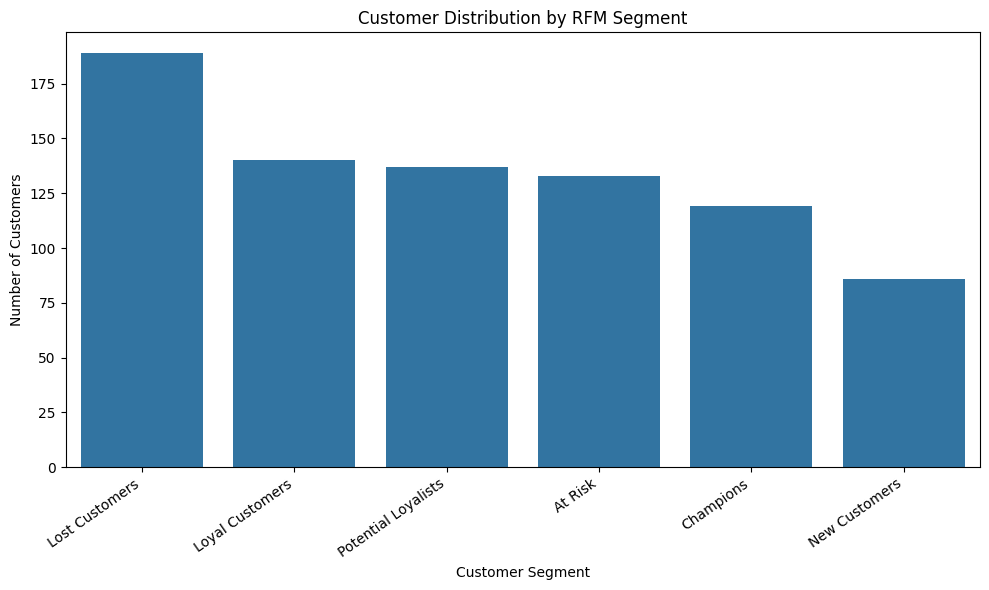

In [39]:
# Step 9.5: Customer Segment Distribution

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.sort_values(
        "Total_Customers", ascending=False
    ),
    x="Customer_Segment",
    y="Total_Customers"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

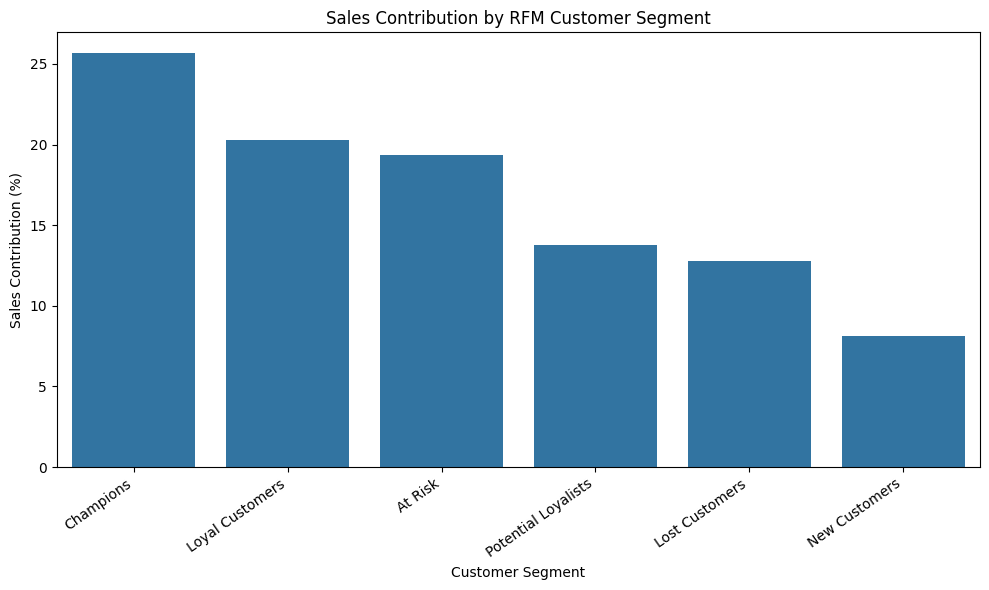

In [40]:
# Step 9.6: Sales Contribution by RFM Segment

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.sort_values(
        "Sales_Contribution_%", ascending=False
    ),
    x="Customer_Segment",
    y="Sales_Contribution_%"
)

plt.title("Sales Contribution by RFM Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Sales Contribution (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [41]:
# Step 9.7: Profit Contribution by RFM Segment

segment_summary["Profit_Margin_%"] = (
    segment_summary["Total_Profit"] /
    segment_summary["Total_Sales"]
) * 100

segment_summary["Profit_Contribution_%"] = (
    segment_summary["Total_Profit"] /
    segment_summary["Total_Profit"].sum()
) * 100

display(
    segment_summary[
        [
            "Customer_Segment",
            "Total_Customers",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%",
            "Profit_Contribution_%"
        ]
    ].sort_values(
        "Total_Profit", ascending=False
    ).round(2)
)

,Customer_Segment,Total_Customers,Total_Sales,Total_Profit,Profit_Margin_%,Profit_Contribution_%
0,At Risk,133,417518.54,69956.88,16.76,25.62
3,Loyal Customers,140,436911.44,68037.14,15.57,24.92
1,Champions,119,553125.20,60782.39,10.99,22.26
2,Lost Customers,189,274779.32,34259.53,12.47,12.55
5,Potential Loyalists,137,296273.09,21519.08,7.26,7.88
4,New Customers,86,175361.88,18458.26,10.53,6.76


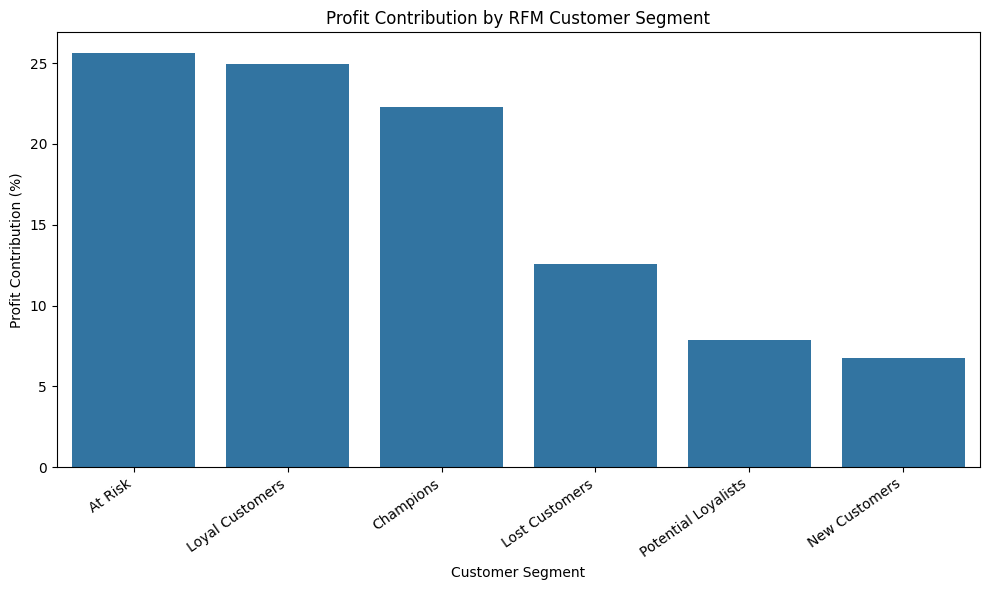

In [42]:
# Step 9.8: Profit Contribution by Customer Segment

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.sort_values(
        "Profit_Contribution_%", ascending=False
    ),
    x="Customer_Segment",
    y="Profit_Contribution_%"
)

plt.title("Profit Contribution by RFM Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit Contribution (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

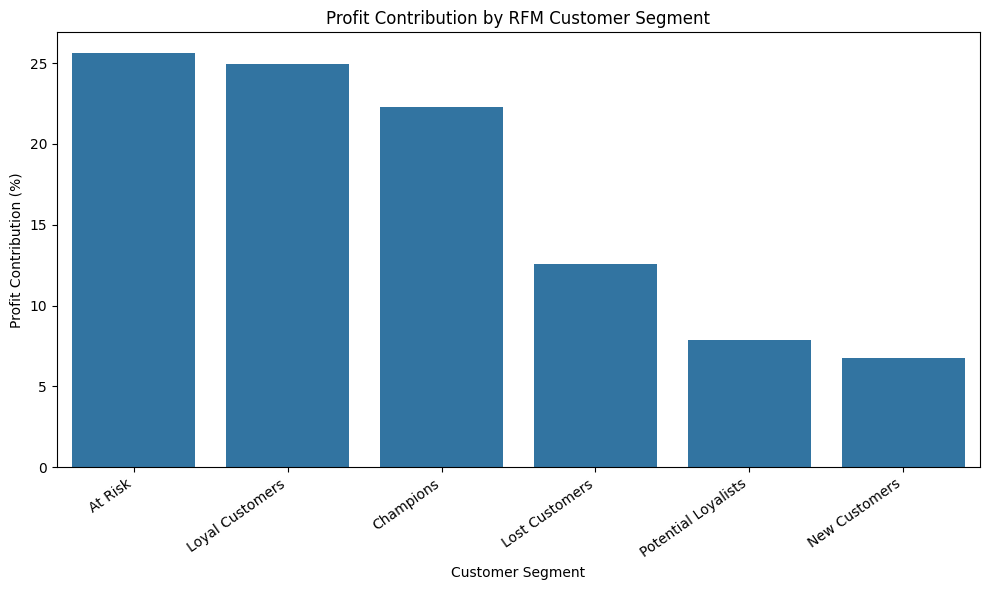

In [43]:
# Step 9.8: Profit Contribution by Customer Segment

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.sort_values(
        "Profit_Contribution_%", ascending=False
    ),
    x="Customer_Segment",
    y="Profit_Contribution_%"
)

plt.title("Profit Contribution by RFM Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit Contribution (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [44]:
# Step 9.9: RFM Validation

print("Total RFM Customers:", len(rfm))
print("Unique Customer IDs:", rfm["Customer ID"].nunique())

print("\nMissing Values:")
display(rfm.isnull().sum())

print("\nCustomer Segment Counts:")
display(rfm["Customer_Segment"].value_counts())

print("\nSales Validation:")
print("RFM Total Sales:", round(rfm["Monetary"].sum(), 2))
print("Historical Sales:", round(rfm_df["Sales"].sum(), 2))

print("\nProfit Validation:")
print("RFM Total Profit:", round(rfm["Total_Profit"].sum(), 2))
print("Historical Profit:", round(rfm_df["Profit"].sum(), 2))

Total RFM Customers: 804
Unique Customer IDs: 804

Missing Values:


,0
Customer ID,0
Last_Order_Date,0
Recency,0
Frequency,0
Monetary,0
Total_Profit,0
R_Score,0
F_Score,0
M_Score,0
RFM_Score,0



Customer Segment Counts:


,count
Customer_Segment,
Lost Customers,189
Loyal Customers,140
Potential Loyalists,137
At Risk,133
Champions,119
New Customers,86



Sales Validation:
RFM Total Sales: 2153969.48
Historical Sales: 2153969.48

Profit Validation:
RFM Total Profit: 273013.27
Historical Profit: 273013.27
